In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [1]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi


Bad key "text.kerning_factor" on line 4 in
/home/wx2203/anaconda3/lib/python3.7/site-packages/matplotlib/mpl-data/stylelib/_classic_test_patch.mplstyle.
You probably need to get an updated matplotlibrc file from
http://github.com/matplotlib/matplotlib/blob/master/matplotlibrc.template
or from the matplotlib source distribution


In [2]:
prefix = '/mnt/staging/' # or '/scratch/' for s1n3/4
step_2_root = str(STEPS / "step_2") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_0_root = str(STEPS / "step_0") + "/"
step_3_root = str(STEPS / "step_3") + "/"
dlc_fullview_root = prefix+'users/wx2203/lidocaine/dlc_fullview_h5s/'
dlc_body_root = prefix+'users/wx2203/lidocaine/dlc_body_h5s/'
video_root = prefix+'users/wx2203/dlc_results_mp4s/lidocaine/'
save_root = prefix+'users/wx2203/new_analysis_locker/pub-locker/'
fetch_path_sensory = str(PREPARES / "sensory-boop-test") + "/"
fetch_path_motor = str(PREPARES / "heterogeneity") + "/"
mouse='cm216'

In [3]:
# files without random stim
f2 = list(set(glob.glob(step_1_root+"*216/[2-9]/run*[B-N]*.mat"))-
         set(glob.glob(step_1_root+"*216/[7]/run*[B-N]*.mat")))


file_spont = f2
file_spont

['/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/6/runJ_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/9/runC_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/2/runF_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/4/runE_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/4/runG_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/5/runI_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/8/runB_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/8/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/4/runL_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/6/runC_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/5/runG_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/analysis/step_1/cm216/8/runE_stim_1.mat',
 '/mnt/staging/users/wx2203/lidocaine/an

In [1]:
with h5py.File(step_0_root+'idx_sorted_500_cm216.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

NameError: name 'h5py' is not defined

In [5]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

RUN missing  cm216_4_runE
RUN missing  cm216_4_runG
RUN missing  cm216_4_runL
RUN missing  cm216_5_runK
RUN missing  cm216_4_runF
RUN missing  cm216_4_runI
RUN missing  cm216_4_runH
RUN missing  cm216_4_runK
RUN missing  cm216_4_runJ


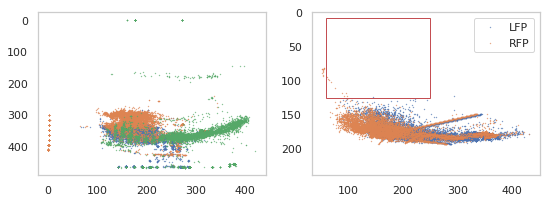

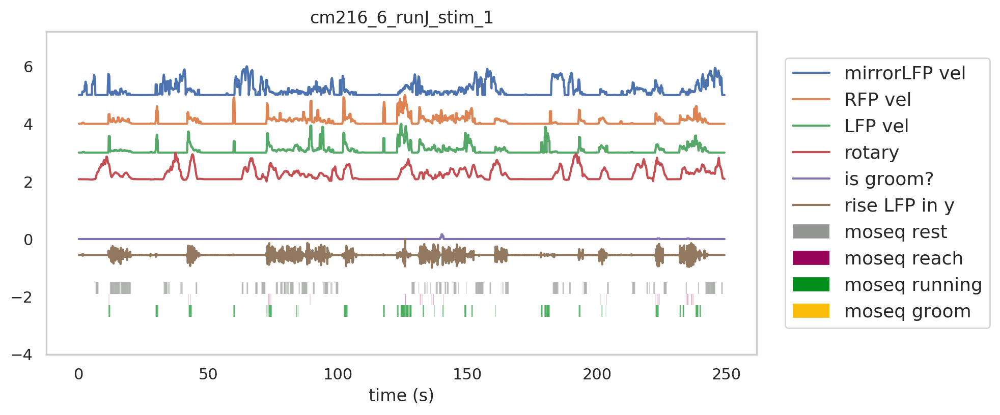

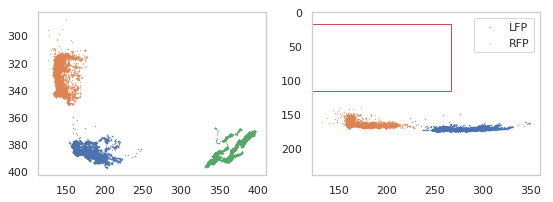

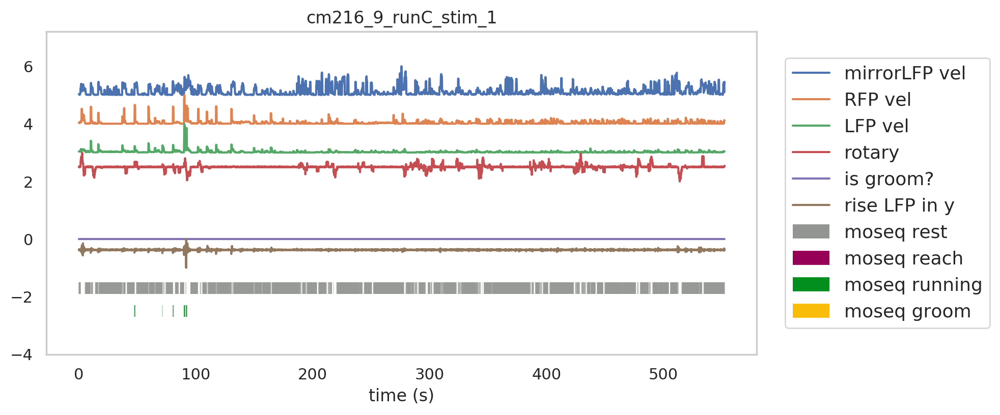

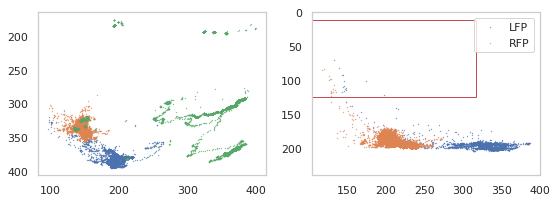

...

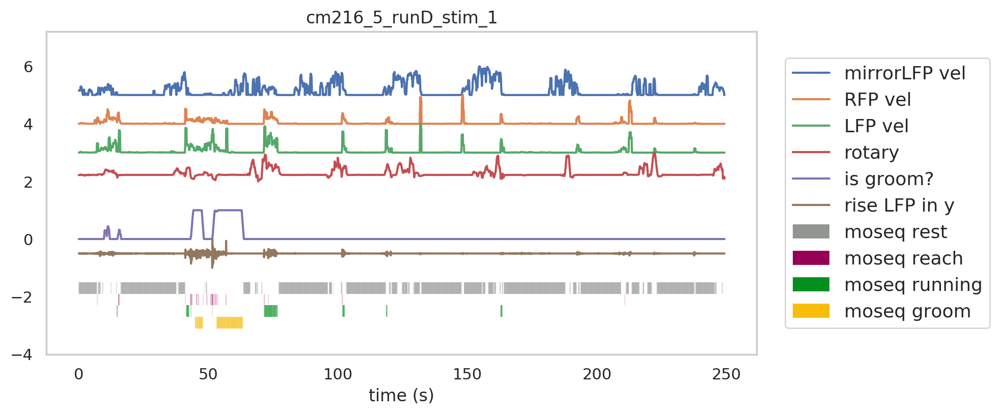

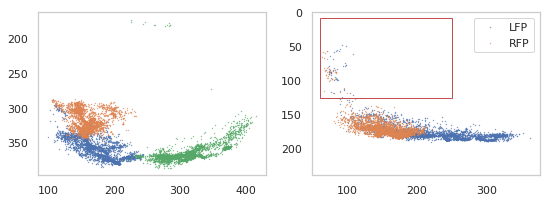

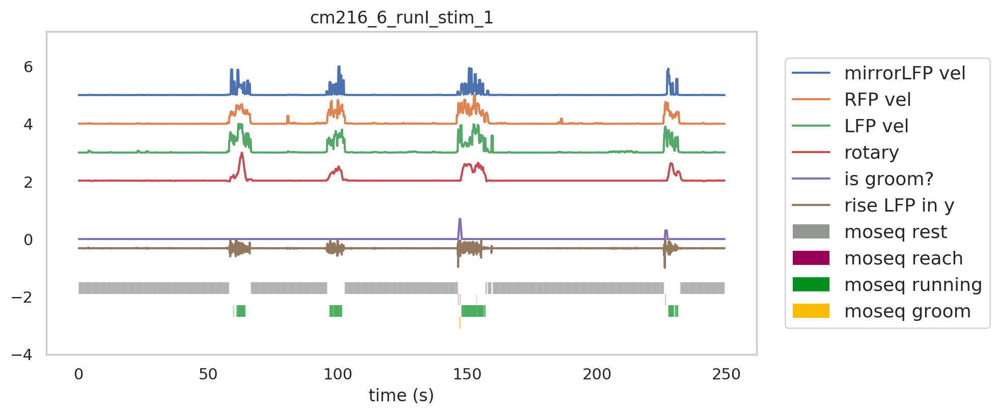

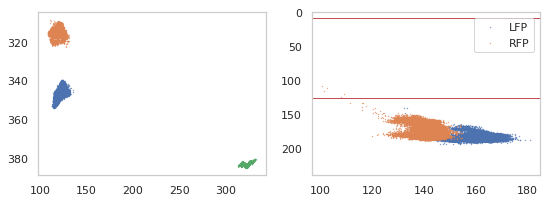

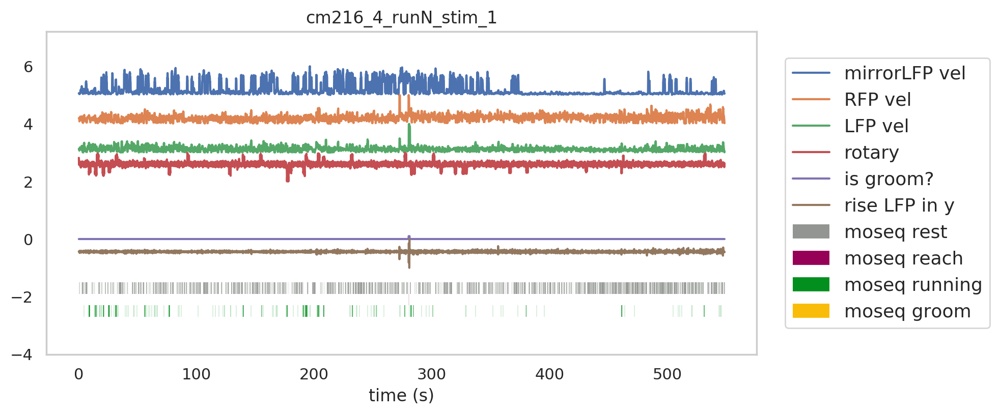

In [7]:
sns.set_style("whitegrid", {'axes.grid' : False})
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

data_joint=pd.DataFrame()
big_df_concat = pd.DataFrame()

for i_file,fname in enumerate(file_spont): 
    
    ################################### identity 
    run_name = fname[-15:-4]
    mouse = fname[-23:-18]
    day = fname[-17:-16]
    mouse_day = mouse+'_'+day
    run = fname[-15:-11]

        
    try:    
        f_config = h5py.File(step_0_root+'crop_groom_'+mouse+'.mat','r')

        x_top_left = np.array(f_config[f_config['xx']['groom'][int(day)-1,0]])[:,0]
        x_botton_right = np.array(f_config[f_config['xx']['groom'][int(day)-1,0]])[:,1]
        y_top_left = np.array(f_config[f_config['yy']['groom'][int(day)-1,0]])[:,0]
        y_botton_right = np.array(f_config[f_config['yy']['groom'][int(day)-1,0]])[:,1]

        out_h = int((x_botton_right - x_top_left))
        out_w = int((y_botton_right - y_top_left)) 
        y = int(x_top_left)
        x = int(y_top_left)

        f_name_dlc = glob.glob(dlc_fullview_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
        #####################cm216-ONLY
        new_df=new_df[:-2]
        #####################cm216-ONLY    

        paws_vel_df = pd.DataFrame()
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        for i_bpt,bpt in enumerate(['mLFP','mRFP','mLHP']):

            p_value = new_df[bpt]['likelihood']
            new_df[bpt]['x'][p_value<0.05]=np.nan
            new_df[bpt]['y'][p_value<0.05]=np.nan       
            # if np.logical_and(mouse=='cm216',np.logical_or(bpt=='LFP',bpt=='RFP')):
            #     new_df[(bpt,'x')][new_df[(bpt,'x')]>240]=np.nan
            #     new_df[(bpt,'y')][new_df[(bpt,'x')]>240]=np.nan
            new_df[bpt] = new_df[bpt].interpolate()
            new_df[bpt] = new_df[bpt].fillna(0) # in case nan in first few rows

            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel).rolling(30).std()
            tocut = vel.shape[0]%3
            if tocut ==0:
                vel = np.mean(vel.values.reshape((-1,3)),axis=1)
            else:
                vel = np.mean(vel[:-tocut].values.reshape((-1,3)),axis=1)
            paws_vel_df[bpt] = vel[500:-505]
        # LFP_vel = np.array(paws_vel_df['LFP'])
        # RFP_vel = np.array(paws_vel_df['RFP'])
        mirrorLFP_vel = np.array(paws_vel_df['mLFP'])
        mirrorRFP_vel = np.array(paws_vel_df['mRFP'])
        mirrorLHP_vel = np.array(paws_vel_df['mLHP'])

        fig = plt.figure(figsize=(9,3))
        ax1 = fig.add_subplot(121)
        # plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
        # plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
        ax1.scatter(new_df['mLFP']['x'],new_df['mLFP']['y'],s=0.1,label='mLFP')
        ax1.scatter(new_df['mRFP']['x'],new_df['mRFP']['y'],s=0.1,label='mRFP')
        ax1.scatter(new_df['mLHP']['x'],new_df['mLHP']['y'],s=0.1,label='mLHP')

        plt.gca().invert_yaxis()


    ##

        f_name_dlc = glob.glob(dlc_body_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level

        paws_vel_df = pd.DataFrame()
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        for i_bpt,bpt in enumerate(['LFP','RFP']):

            p_value = new_df[bpt]['likelihood']
            new_df[bpt]['x'][p_value<0.05]=np.nan
            new_df[bpt]['y'][p_value<0.05]=np.nan       
            new_df[bpt] = new_df[bpt].interpolate()
            new_df[bpt] = new_df[bpt].fillna(0) # in case nan in first few rows

            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel).rolling(30).std()
            tocut = vel.shape[0]%3
            if tocut ==0:
                vel = np.mean(vel.values.reshape((-1,3)),axis=1)
            else:
                vel = np.mean(vel[:-tocut].values.reshape((-1,3)),axis=1)
            paws_vel_df[bpt] = vel[500:-505]
        LFP_vel = np.array(paws_vel_df['LFP'])
        RFP_vel = np.array(paws_vel_df['RFP'])

        ax2 = fig.add_subplot(122)
        ax2.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
        ax2.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')

        rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
        ax2.set_ylim([0,240])
        ax2.legend()
        ax2.add_patch(rect)
        plt.gca().invert_yaxis()


        rise_LFP = new_df['LFP']['y'].copy().diff().rolling(5).std().rolling(3).mean()
        if tocut ==0:
            rise_LFP = np.mean(rise_LFP.values.reshape((-1,3)),axis=1) #(11980,)
        else:
            rise_LFP = np.mean(rise_LFP[:-tocut].values.reshape((-1,3)),axis=1) #(11980,)
        rise_LFP = rise_LFP[500:-505] 
        # rise_LFP = normalize(stats.zscore(rise_LFP[500:-505]))

        rise_LFP_raw = new_df['LFP']['y'].copy().diff()
        if tocut ==0:
            rise_LFP_raw = np.mean(rise_LFP_raw.values.reshape((-1,3)),axis=1) #(11980,)
        else:
            rise_LFP_raw = np.mean(rise_LFP_raw[:-tocut].values.reshape((-1,3)),axis=1) #(11980,)
        rise_LFP_raw = rise_LFP_raw[500:-505]   

        is_groom_LFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
        is_groom_RFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)
        is_groom = np.logical_or(is_groom_LFP,is_groom_RFP)
        is_groom_smooth = is_groom.rolling(50).mean()
        if tocut ==0:
            is_groom_smooth_ds = np.mean(is_groom_smooth.values.reshape((-1,3)),axis=1) #(11980,)
        else:
            is_groom_smooth_ds = np.mean(is_groom_smooth[:-tocut].values.reshape((-1,3)),axis=1) #(11980,)

        is_groom_smooth_ds = is_groom_smooth_ds[500:-505]


    except:
        print('RUN missing ',mouse_day+'_'+run)   
        continue


    LFP_vel_norm = stats.zscore(LFP_vel)
    RFP_vel_norm = stats.zscore(RFP_vel)    
    mirrorLFP_vel_norm = stats.zscore(mirrorLFP_vel)
    mirrorRFP_vel_norm = stats.zscore(mirrorRFP_vel)
    mirrorLHP_vel_norm = stats.zscore(mirrorLHP_vel)
    
    ################################### rotary (11980, 1)

    f = h5py.File(fname,'r')
    m=f['m']
    # a=np.array(m['aux']).T
    a=np.array(m['DAQ_ds'])[:,6]
    # if a.shape[0]==2:
    #     a=a.T
    rot = np.rad2deg(np.unwrap(a))
    rot = np.diff(rot)
    z = np.abs(stats.zscore(rot))
    threshold = 3
    outlier_ind = np.squeeze(np.where(z > 3))
    rot[outlier_ind]=np.nan
    # downsample by 3
    # rot_speed = np.array(np.squeeze(pd.DataFrame(rot).interpolate().rolling(60).std().fillna(0)))[::3]
    rot_raw = np.array(np.squeeze(pd.DataFrame(rot).interpolate().rolling(30).mean().fillna(0)))   

    # rot_speed = stats.zscore(rot_speed[500:-505])
    rot_raw = rot_raw[500:]
    rot_raw = rot_raw[:len(LFP_vel_norm)]
    rot_raw = stats.zscore(rot_raw)


    
    big_df = pd.DataFrame()
    rot_zscore_abs=np.abs(rot_raw)
    
    all_bev = ['LFP_vel_norm','RFP_vel_norm','mirrorLFP_vel_norm',
              'mirrorRFP_vel_norm','mirrorLHP_vel_norm',
              'rot_raw','rot_zscore_abs']
    for bev in all_bev:
        exec("big_df[bev] = normalize({})".format(bev))
    big_df['rise_LFP']=rise_LFP
    
    big_df['is_groom_smooth_ds']=is_groom_smooth_ds
    
    #behavior segmentation
    # is_whisking = np.logical_and(np.logical_and(big_df['whisk_vel_norm']>0.3, 
    #                           big_df['LFP_vel_norm']<0.1),big_df['rot_raw']<0.2)
    is_reach = big_df['rise_LFP']>17
    is_running = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.2, 
                              big_df['LFP_vel_norm']>0.2),big_df['rot_zscore_abs']>0.15),~is_reach)
    is_groom = np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']>0.5, 
                              big_df['rot_zscore_abs']<0.12),~is_reach)    
    is_rest = np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
                              big_df['LFP_vel_norm']<0.1),big_df['rot_zscore_abs']<0.15)

    moseq_list = ['is_rest','is_reach','is_running','is_groom']
    for moseq in moseq_list:
        exec("big_df[moseq] = {}".format(moseq))
        
    tmp = pd.concat([big_df], keys=[mouse_day+'_'+run], names=['row_level'])
    big_df_concat = big_df_concat.append(tmp)


    plt.figure(figsize=(9,4.2),dpi=200)
    T=LFP_vel_norm.shape[0]
    t_ax=np.divide(range(T),20)

    plt.plot(t_ax,normalize(mirrorLHP_vel_norm)+5,label='mirrorLFP vel')                           
    plt.plot(t_ax,normalize(RFP_vel_norm)+4,label='RFP vel')            
    plt.plot(t_ax,normalize(LFP_vel_norm)+3,label='LFP vel')
    plt.plot(t_ax,normalize(rot_raw)+2,label='rotary')
    plt.plot(t_ax,is_groom_smooth_ds,label='is groom?')
    plt.plot(t_ax,normalize(rise_LFP_raw)-1,label='rise LFP in y')
    plt.xlabel('time (s)')
    col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
    col_list_palette = sns.xkcd_palette(col_list)
    
    # moseq
    for i, moseq in enumerate(moseq_list):
        plt.vlines(t_ax[np.where(big_df[moseq]==True)], -1.5-i*0.4, -1.9-i*0.4,linewidth=0.1,color=col_list_palette[i])
        plt.vlines(t_ax[0], 8, 9,linewidth=10,color=col_list_palette[i],label='moseq '+moseq[3:])#for the legend

    plt.ylim([-4,7.2])
    plt.title(mouse_day+'_'+run_name)
    plt.legend(bbox_to_anchor=(1.04,0.5), loc="center left", borderaxespad=0,fontsize = 13)

    

In [94]:
save_root = str(PREPARES / "behavior-segment") + "/"
save_pickle(big_df_concat,save_root+'big_df_concat_'+mouse)

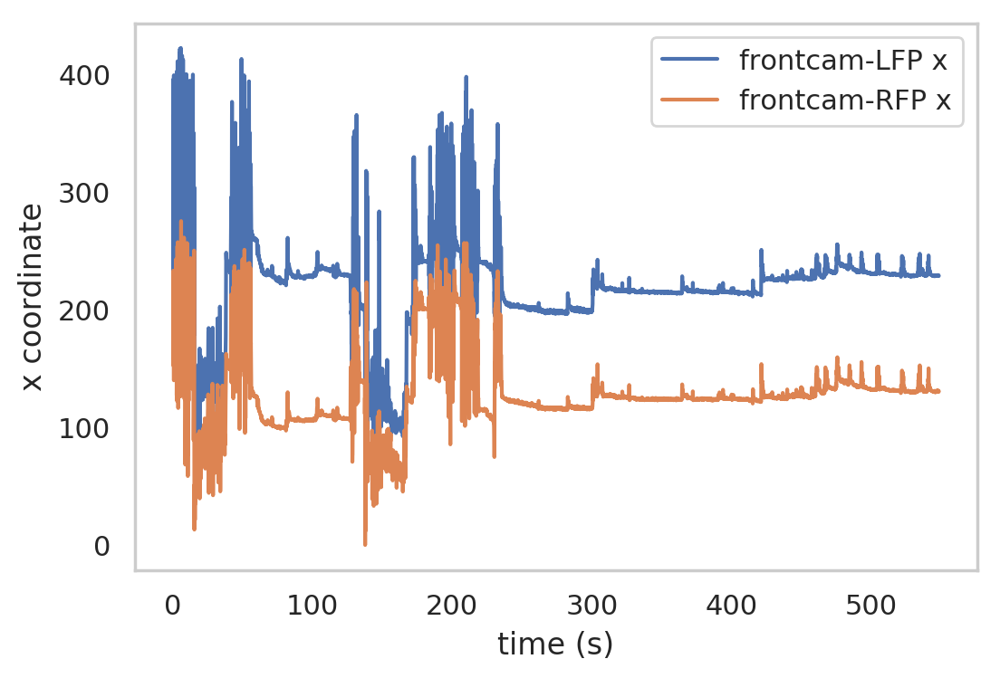

In [36]:
plt.figure(dpi=200)
T = len(data_pot.loc[:,('cam0','LFP','x')])
t_ax=np.divide(range(T),20)
plt.plot(t_ax,data_pot.loc[:,('cam0','LFP','x')],label='frontcam-LFP x')
plt.plot(t_ax,data_pot.loc[:,('cam0','RFP','x')],label='frontcam-RFP x')
plt.xlabel('time (s)')
plt.ylabel('x coordinate')
plt.legend()
# plt.plot(data_pot.loc[:,('cam1','RHP','x')],label='mirrorcam-RHP-x')
# plt.plot(data_pot.loc[:,('cam1','LHP','x')],label='mirrorcam-LHP-x')